In [1]:
# Load the customer segmentation dataset
import pandas as pd
from pathlib import Path

data_path = Path("../data/processed/customer_segments.csv")

customer_data = pd.read_csv(data_path)

print("Dataset shape:", customer_data.shape)

customer_data.head()

Dataset shape: (96096, 4)


,customer_unique_id,frequency,recency,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,1,161,Recent One-Time
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,164,Recent One-Time
2,0000f46a3911fa3c0805444483337064,1,586,Inactive One-Time
3,0000f6ccb0745a6a4b88665a16c9f078,1,370,Inactive One-Time
4,0004aac84e0df4da2b147fca70cf8255,1,337,Inactive One-Time


In [2]:
# Check customer data quality

# Check column names and data types
print("Dataset information:")
customer_data.info()

# Check missing values
print("\nMissing values:")
print(customer_data.isnull().sum())

# Check duplicate customer IDs
print("\nDuplicate customer IDs:")
print(customer_data["customer_unique_id"].duplicated().sum())

# Check customer segments
print("\nCustomer segment distribution:")
print(customer_data["segment"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 96096 entries, 0 to 96095
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   customer_unique_id  96096 non-null  str  
 1   frequency           96096 non-null  int64
 2   recency             96096 non-null  int64
 3   segment             96096 non-null  str  
dtypes: int64(2), str(2)
memory usage: 7.4 MB

Missing values:
customer_unique_id    0
frequency             0
recency               0
segment               0
dtype: int64

Duplicate customer IDs:
0

Customer segment distribution:
segment
Inactive One-Time    66327
Recent One-Time      26772
At-Risk Repeat        2025
Active Repeat          972
Name: count, dtype: int64


In [3]:
# Prepare customer features

# Create a separate copy of the dataset
customer_features = customer_data.copy()

# Select numerical customer features
feature_columns = ["frequency", "recency"]

X = customer_features[feature_columns].copy()

# Display the feature dataset
print("Feature dataset shape:", X.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nFirst five records:")
display(X.head())

print("\nFeature statistics:")
display(X.describe())

Feature dataset shape: (96096, 2)

Selected features:
['frequency', 'recency']

First five records:


,frequency,recency
0,1,161
1,1,164
2,1,586
3,1,370
4,1,337



Feature statistics:


,frequency,recency
count,96096.000000,96096.000000
mean,1.034809,288.735691
std,0.214384,153.414676
min,1.000000,1.000000
25%,1.000000,164.000000
50%,1.000000,269.000000
75%,1.000000,398.000000
max,17.000000,773.000000


In [4]:
# Scale customer features

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale the numerical features
X_scaled = scaler.fit_transform(X)

# Convert scaled values into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

print("Scaled feature dataset shape:", X_scaled_df.shape)

print("\nFirst five scaled records:")
display(X_scaled_df.head())

print("\nScaled feature statistics:")
display(X_scaled_df.describe().round(2))

Scaled feature dataset shape: (96096, 2)

First five scaled records:


,frequency,recency
0,-0.162368,-0.832621
1,-0.162368,-0.813067
2,-0.162368,1.937662
3,-0.162368,0.529706
4,-0.162368,0.314602



Scaled feature statistics:


,frequency,recency
count,96096.00,96096.00
mean,-0.00,0.00
std,1.00,1.00
min,-0.16,-1.88
25%,-0.16,-0.81
50%,-0.16,-0.13
75%,-0.16,0.71
max,74.47,3.16


In [5]:
# Customer segmentation using K-Means

from sklearn.cluster import KMeans

# Choose the number of customer groups
number_of_clusters = 4

# Create the K-Means model
kmeans = KMeans(
    n_clusters=number_of_clusters,
    random_state=42,
    n_init=10
)

# Fit the model using scaled customer features
customer_clusters = kmeans.fit_predict(X_scaled_df)

# Add cluster labels to the customer dataset
customer_features["cluster"] = customer_clusters

# Display the number of customers in each cluster
print("Customer cluster distribution:")
print(customer_features["cluster"].value_counts().sort_index())

# Display the first five customers
print("\nSample customer records:")
display(
    customer_features[
        ["customer_unique_id", "frequency", "recency", "cluster"]
    ].head()
)

Customer cluster distribution:
cluster
0    35268
1    22087
2    35744
3     2997
Name: count, dtype: int64

Sample customer records:


,customer_unique_id,frequency,recency,cluster
0,0000366f3b9a7992bf8c76cfdf3221e2,1,161,2
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,164,2
2,0000f46a3911fa3c0805444483337064,1,586,1
3,0000f6ccb0745a6a4b88665a16c9f078,1,370,0
4,0004aac84e0df4da2b147fca70cf8255,1,337,0


In [6]:
# Analyze customer clusters

# Calculate summary statistics for each cluster
cluster_summary = customer_features.groupby("cluster").agg(
    total_customers=("customer_unique_id", "count"),
    average_frequency=("frequency", "mean"),
    average_recency=("recency", "mean"),
    minimum_frequency=("frequency", "min"),
    maximum_frequency=("frequency", "max")
)

# Round numerical values
cluster_summary = cluster_summary.round(2)

print("Customer Cluster Summary:")
display(cluster_summary)

Customer Cluster Summary:


,total_customers,average_frequency,average_recency,minimum_frequency,maximum_frequency
cluster,,,,,
0,35268,1.00,305.69,1,1
1,22087,1.00,509.54,1,1
2,35744,1.00,137.20,1,1
3,2997,2.12,269.21,2,17


In [7]:
# Assigning names to each customer clusters

# Define names based on cluster characteristics
cluster_names = {
    0: "Moderately Inactive One-Time",
    1: "Long-Inactive One-Time",
    2: "Recently Active One-Time",
    3: "Repeat Customers"
}

# Add descriptive cluster names
customer_features["cluster_name"] = (
    customer_features["cluster"].map(cluster_names)
)

# Display the distribution
print("Customer Groups:")
print(customer_features["cluster_name"].value_counts())

# Display sample records
print("\nSample customer records:")
display(
    customer_features[
        [
            "customer_unique_id",
            "frequency",
            "recency",
            "cluster",
            "cluster_name"
        ]
    ].head()
)

Customer Groups:
cluster_name
Recently Active One-Time        35744
Moderately Inactive One-Time    35268
Long-Inactive One-Time          22087
Repeat Customers                 2997
Name: count, dtype: int64

Sample customer records:


,customer_unique_id,frequency,recency,cluster,cluster_name
0,0000366f3b9a7992bf8c76cfdf3221e2,1,161,2,Recently Active One-Time
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,164,2,Recently Active One-Time
2,0000f46a3911fa3c0805444483337064,1,586,1,Long-Inactive One-Time
3,0000f6ccb0745a6a4b88665a16c9f078,1,370,0,Moderately Inactive One-Time
4,0004aac84e0df4da2b147fca70cf8255,1,337,0,Moderately Inactive One-Time


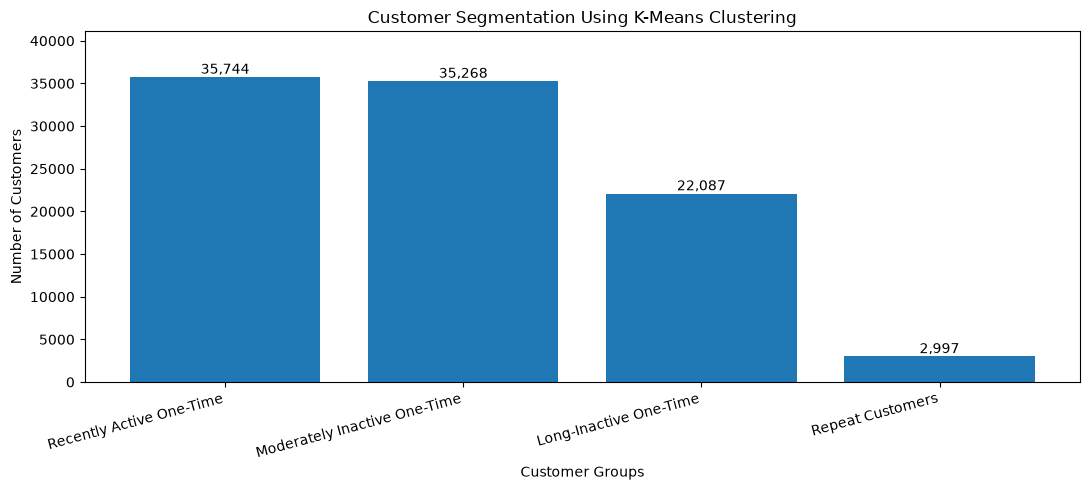

In [8]:
#Visualize customer clusters

import matplotlib.pyplot as plt

# Count customers in each cluster
cluster_counts = customer_features["cluster_name"].value_counts()

# Create the bar chart
plt.figure(figsize=(11, 5))

bars = plt.bar(
    cluster_counts.index,
    cluster_counts.values
)

# Add customer counts above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

# Add chart labels
plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("Customer Groups")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15, ha="right")
plt.ylim(0, cluster_counts.max() * 1.15)

plt.tight_layout()
plt.show()

In [10]:
# Save K-Means customer segmentation results

from pathlib import Path

# Select customer information and clustering results
cluster_results = customer_features[
    [
        "customer_unique_id",
        "frequency",
        "recency",
        "cluster",
        "cluster_name"
    ]
].copy()

# Create the output folder if needed
output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# Save results as a CSV file
output_file = output_folder / "customer_clusters.csv"

cluster_results.to_csv(output_file, index=False)

print("Customer clustering results saved successfully!")
print("File location:", output_file)

print("\nDataset shape:")
print(cluster_results.shape)

print("\nDataset columns:")
print(cluster_results.columns.tolist())

print("\nFirst five records:")
display(cluster_results.head())

Customer clustering results saved successfully!
File location: ../data/processed/customer_clusters.csv

Dataset shape:
(96096, 5)

Dataset columns:
['customer_unique_id', 'frequency', 'recency', 'cluster', 'cluster_name']

First five records:


,customer_unique_id,frequency,recency,cluster,cluster_name
0,0000366f3b9a7992bf8c76cfdf3221e2,1,161,2,Recently Active One-Time
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,164,2,Recently Active One-Time
2,0000f46a3911fa3c0805444483337064,1,586,1,Long-Inactive One-Time
3,0000f6ccb0745a6a4b88665a16c9f078,1,370,0,Moderately Inactive One-Time
4,0004aac84e0df4da2b147fca70cf8255,1,337,0,Moderately Inactive One-Time


In [11]:
# Evaluate K-Means clustering

from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Select the features used for clustering
X = customer_features[["frequency", "recency"]]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Retrieve the cluster labels
cluster_labels = customer_features["cluster"]

# Calculate silhouette score using a sample
score = silhouette_score(
    X_scaled,
    cluster_labels,
    sample_size=10000,
    random_state=42
)

print("K-Means Clustering Evaluation")
print("-----------------------------")
print("Number of clusters:", cluster_labels.nunique())
print("Silhouette Score:", round(score, 4))

K-Means Clustering Evaluation
-----------------------------
Number of clusters: 4
Silhouette Score: 0.5825


In [12]:
# Compare different numbers of clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Test different cluster counts
cluster_scores = []

for k in [3, 4, 5, 6]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    cluster_scores.append({
        "Number of Clusters": k,
        "Silhouette Score": round(score, 4)
    })

# Display comparison results
comparison_df = pd.DataFrame(cluster_scores)

print("K-Means Cluster Comparison:")
display(comparison_df)

best_result = comparison_df.loc[
    comparison_df["Silhouette Score"].idxmax()
]

print(
    "\nBest number of clusters:",
    int(best_result["Number of Clusters"])
)

K-Means Cluster Comparison:


,Number of Clusters,Silhouette Score
0,3,0.5971
1,4,0.5882
2,5,0.5904
3,6,0.5618



Best number of clusters: 3


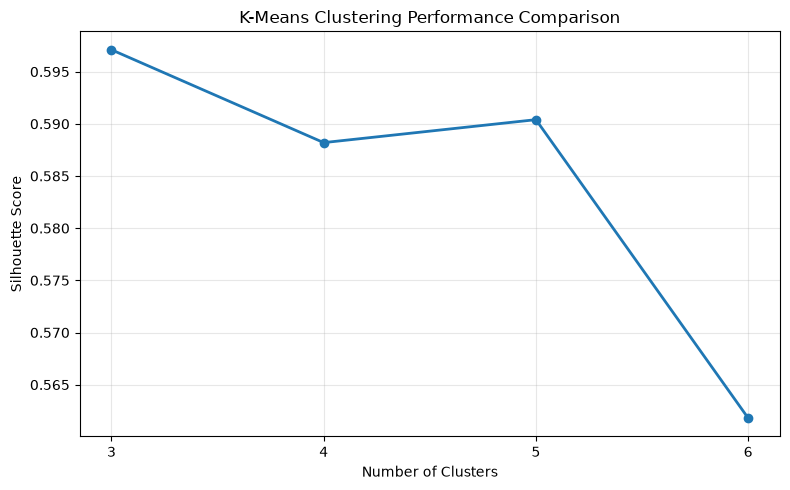

In [13]:
# Visualize K-Means cluster comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["Number of Clusters"],
    comparison_df["Silhouette Score"],
    marker="o",
    linewidth=2
)

plt.title("K-Means Clustering Performance Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.xticks(comparison_df["Number of Clusters"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

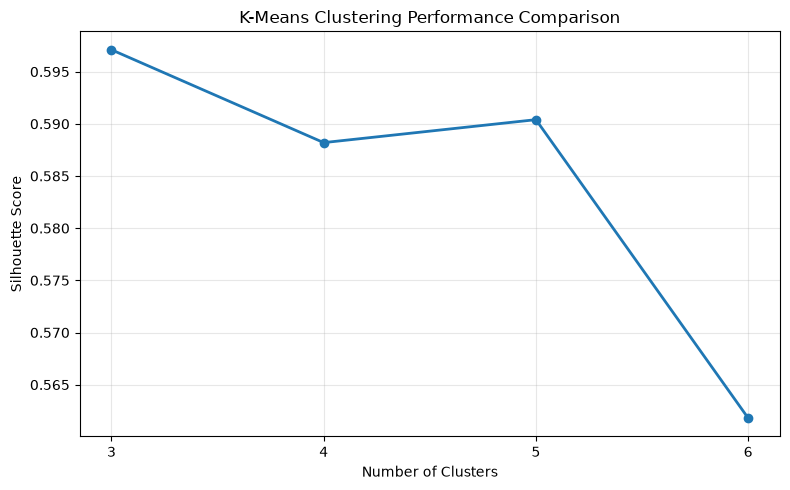

Evaluation results saved successfully!
CSV file: ../reports/kmeans_evaluation.csv
Chart file: ../reports/kmeans_comparison.png


In [14]:
# Save K-Means evaluation results

from pathlib import Path
import matplotlib.pyplot as plt

# Create reports folder
reports_folder = Path("../reports")
reports_folder.mkdir(parents=True, exist_ok=True)

# Save the comparison table
csv_path = reports_folder / "kmeans_evaluation.csv"

comparison_df.to_csv(csv_path, index=False)

# Create and save the comparison chart
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["Number of Clusters"],
    comparison_df["Silhouette Score"],
    marker="o",
    linewidth=2
)

plt.title("K-Means Clustering Performance Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(comparison_df["Number of Clusters"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_path = reports_folder / "kmeans_comparison.png"

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Evaluation results saved successfully!")
print("CSV file:", csv_path)
print("Chart file:", chart_path)